# 01 — Traction d'un pneu agricole sur sol meuble

**Objectif** : prédire l'effort au crochet (*drawbar pull*) DP d'un pneu 650/65R38 générique en
fonction du glissement $s$, pour plusieurs sols et pressions de gonflage.

**Modèle** (détails et sources dans `agritire/terramechanics.py` et `report.md`) :

| Brique | Équation | Source |
|---|---|---|
| Pression–enfoncement | $\sigma = (k_c/b + k_\varphi)\,z^n$ | Bekker (1969) |
| Cisaillement | $\tau = (c + \sigma\tan\varphi)\,(1 - e^{-j/K})$ | Janosi & Hanamoto (1961) |
| Déplacement de cisaillement sur l'arc | $j(\theta) = R[(\theta_1-\theta) - (1-s)(\sin\theta_1 - \sin\theta)]$ | Wong & Reece (1967) |
| Équilibre vertical | $W = Rb\int(\sigma\cos\theta + \tau\sin\theta)\,d\theta + b\int_{\text{méplat}}\sigma\,d\xi$ | — |
| Effort au crochet | $DP = H - R_c$ | Wong (2008) |

Le pneu est **rigide** si $p_i + p_c \ge p_{gcr}$ (pression sous une roue rigide équivalente), sinon il
**s'écrase** : contact = arc avant + méplat à la pression $p_g = p_i + p_c$ (Bekker 1969 ; Wong 2008).

**Hypothèses principales** : régime permanent, sol homogène, pas de bulldozing ni de rebond élastique du
sol, pas d'effet des crampons, pas d'hystérésis interne du pneu, $p_c = 20$ kPa (hypothèse).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agritire import plotting
plotting.setup()
pd.set_option("display.precision", 3)

from agritire.soil import SOILS
from agritire.terramechanics import (Tire, traction, traction_curve, critical_ground_pressure,
                                     rigid_sinkage, rigid_wheel_sinkage_bekker)
tire = Tire()
W = 30e3   # charge par roue [N] (~3 t)
MODE_FR = {"flexible": "souple", "rigid": "rigide"}
tire

Tire(diameter=1.81, width=0.65, section_height=0.42, inflation=120000.0, carcass_pressure=20000.0, name='650/65R38 (générique)')

## 1. Paramètres de sol (Wong, 2008)
$k_c$ en kN/m$^{n+1}$, $k_\varphi$ en kN/m$^{n+2}$, $c$ en kPa. **$K$ est une hypothèse** (ordre de
grandeur 1–2,5 cm cité pour les sols meubles), recalée au notebook 04.

In [2]:
pd.DataFrame([dict(clé=k, sol=s.name, n=s.n, kc=s.kc, kphi=s.kphi, c_kPa=s.c, phi_deg=s.phi_deg,
                   K_m=s.K, source=s.source) for k, s in SOILS.items()]).set_index("clé")

,sol,n,kc,kphi,c_kPa,phi_deg,K_m,source
clé,,,,,,,,
dry_sand,Sable sec (LLL),1.10,0.99,1528.43,1.04,28.0,0.025,"Wong, J.Y. (2008), Theory of Ground Vehicles, ..."
sandy_loam,"Limon sableux (LLL, 15 %)",0.70,5.27,1515.04,1.72,29.0,0.020,"Wong, J.Y. (2008), Theory of Ground Vehicles, ..."
clayey_soil,"Sol argileux (Thaïlande, 38 %)",0.50,13.19,692.15,4.14,13.0,0.010,"Wong, J.Y. (2008), Theory of Ground Vehicles, ..."
clayey_loam,"Limon argileux (North Gower, 46 %)",0.73,41.60,2471.00,6.10,26.6,0.015,"Wong, J.Y. (2008), Theory of Ground Vehicles, ..."


## 2. Pression critique et mode de fonctionnement
Pour $W$ = 30 kN, on compare $p_g = p_i + p_c$ à la pression critique $p_{gcr}$. On vérifie aussi
l'enfoncement de la roue rigide obtenu par intégration numérique contre la formule approchée de Bekker
$z_0 = [3W/((3-n)(k_c + b k_\varphi)\sqrt{D})]^{2/(2n+1)}$.

In [3]:
rows = []
for k, s in SOILS.items():
    z_num = rigid_sinkage(tire, s, W)
    z_bek = rigid_wheel_sinkage_bekker(s, W, tire.diameter, tire.width)
    rows.append(dict(sol=k, p_gcr_kPa=critical_ground_pressure(tire, s, W) / 1e3,
                     z_rigide_num_cm=100 * z_num, z_rigide_Bekker_cm=100 * z_bek,
                     ecart_pct=100 * (z_num / z_bek - 1)))
pd.DataFrame(rows).set_index("sol")

,p_gcr_kPa,z_rigide_num_cm,z_rigide_Bekker_cm,ecart_pct
sol,,,,
dry_sand,148.379,11.990,12.393,-3.250
sandy_loam,199.375,5.476,5.289,3.542
clayey_soil,176.091,6.109,5.778,5.725
clayey_loam,238.471,3.924,3.795,3.400


L'écart numérique/analytique est de quelques % : la formule de Bekker approxime l'arc par une parabole,
elle est donc d'autant moins précise que l'enfoncement est grand. C'est une **vérification croisée**,
pas une validation physique.

## 3. Distribution des contraintes le long du contact

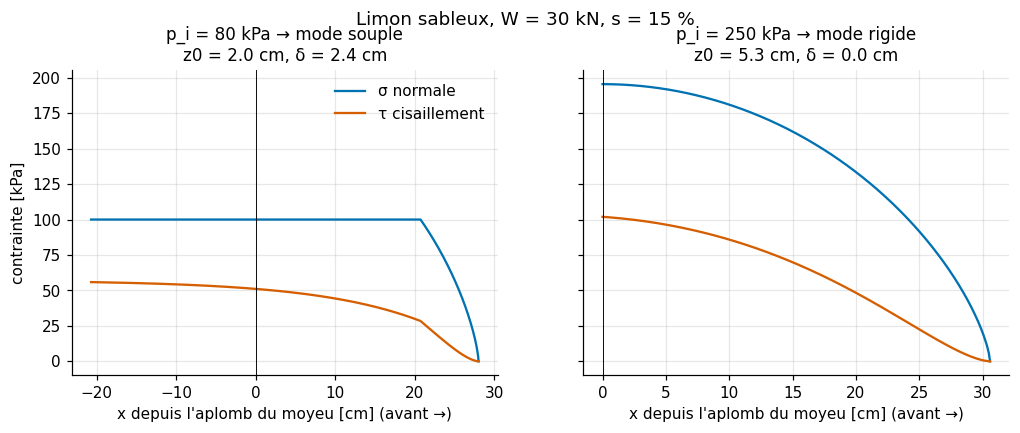

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
soil = SOILS["sandy_loam"]
for ax, p_i in zip(axes, (80e3, 250e3)):
    r, prof = traction(tire.with_(inflation=p_i), soil, W, 0.15, profile=True)
    ax.plot(prof.x * 100, prof.sigma / 1e3, label="σ normale")
    ax.plot(prof.x * 100, prof.tau / 1e3, label="τ cisaillement")
    ax.axvline(0, color="k", lw=0.6)
    ax.set_title(f"p_i = {p_i/1e3:.0f} kPa → mode {MODE_FR[r.mode]}\nz0 = {100*r.sinkage:.1f} cm, δ = {100*r.deflection:.1f} cm")
    ax.set_xlabel("x depuis l'aplomb du moyeu [cm] (avant →)")
axes[0].set_ylabel("contrainte [kPa]")
axes[0].legend()
fig.suptitle("Limon sableux, W = 30 kN, s = 15 %", y=1.03)
plotting.save(fig, "01_contraintes_contact");

- À **basse pression** (gauche), le pneu s'écrase : un méplat à pression quasi uniforme $p_g$ s'ajoute à
  l'arc d'entrée. L'enfoncement est plus faible et le contact plus long.
- À **haute pression** (droite), le pneu se comporte comme une roue rigide : la contrainte normale est
  concentrée sous le moyeu, l'ornière est plus profonde.
- $\tau$ croît de l'avant vers l'arrière du contact car le déplacement de cisaillement $j$ s'accumule.

## 4. Courbes traction / glissement pour quatre sols

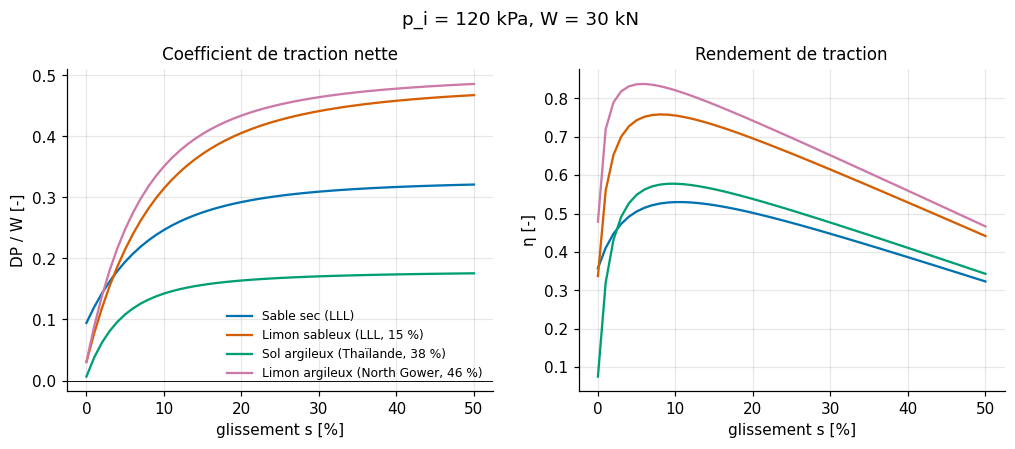

In [5]:
slips = np.linspace(0, 0.5, 51)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for k, s in SOILS.items():
    df = traction_curve(tire, s, W, slips)
    axes[0].plot(100 * df.slip, df.net_traction_ratio, label=s.name)
    axes[1].plot(100 * df.slip, df.tractive_efficiency, label=s.name)
axes[0].set(xlabel="glissement s [%]", ylabel="DP / W [-]", title="Coefficient de traction nette")
axes[1].set(xlabel="glissement s [%]", ylabel="η [-]", title="Rendement de traction")
axes[0].axhline(0, color="k", lw=0.6)
axes[0].legend(fontsize=8)
fig.suptitle(f"p_i = {tire.inflation/1e3:.0f} kPa, W = 30 kN", y=1.02)
plotting.save(fig, "01_traction_sols");

Lecture d'ingénieur :
- l'effort au crochet sature avec le glissement (limite de Mohr–Coulomb $cA + W\tan\varphi$) ;
- le **rendement** passe par un maximum vers 5–15 % de glissement : c'est la plage de fonctionnement
  visée en pratique (au-delà, l'énergie part dans le cisaillement du sol, en deçà la résistance de
  compaction pèse relativement plus) ;
- le **sable sec** (cohésion quasi nulle, enfoncement important) et le **sol argileux à φ = 13°** sont les
  plus défavorables.

**Glissement nul ≠ traction nulle.** À $s = 0$ défini par rapport au rayon libre $R$, la cinématique de
l'arc produit déjà un déplacement de cisaillement $j(\theta) = R[(\theta_1-\theta) - (\sin\theta_1-\sin\theta)]
= O(\theta_1^3)$ : le point de roulement libre (DP = 0) n'est pas exactement à $s = 0$. Pour comparer à
des essais, il faut donc utiliser la **même définition du glissement de référence** (ASABE S296 : roue
autopropulsée sur sol dur). Le modèle d'empreinte plane donne, lui, exactement $H(0) = 0$ et
$DP(0) = -R_c$ (vérifié dans `tests/`).

## 5. Effet de la pression de gonflage

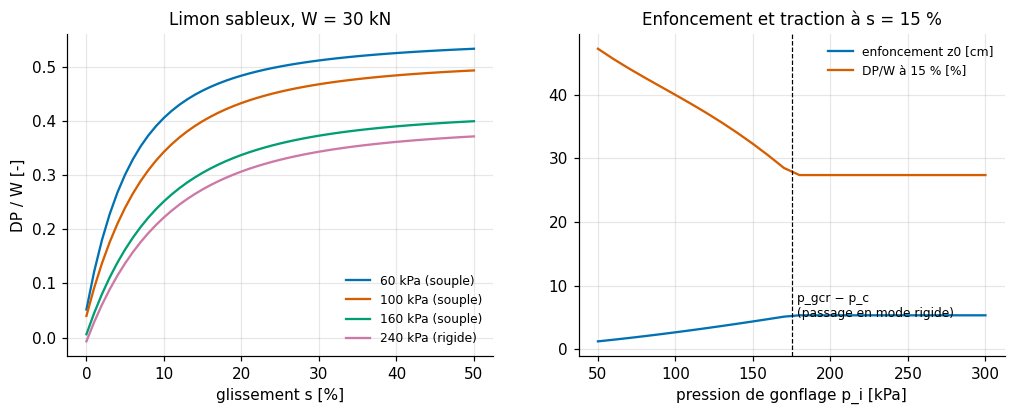

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
soil = SOILS["sandy_loam"]
for p_i in (60e3, 100e3, 160e3, 240e3):
    df = traction_curve(tire.with_(inflation=p_i), soil, W, slips)
    axes[0].plot(100 * df.slip, df.net_traction_ratio, label=f"{p_i/1e3:.0f} kPa ({MODE_FR[df['mode'].iloc[15]]})")
pressures = np.linspace(50e3, 300e3, 26)
res = [traction(tire.with_(inflation=p), soil, W, 0.15) for p in pressures]
axes[1].plot(pressures / 1e3, [100 * r.sinkage for r in res], label="enfoncement z0 [cm]")
axes[1].plot(pressures / 1e3, [100 * r.net_traction_ratio for r in res], label="DP/W à 15 % [%]")
pcr = critical_ground_pressure(tire, soil, W, 0.15) - tire.carcass_pressure
axes[1].axvline(pcr / 1e3, color="k", ls="--", lw=0.8)
axes[1].text(pcr / 1e3 + 3, 5, "p_gcr − p_c\n(passage en mode rigide)", fontsize=8)
axes[0].set(xlabel="glissement s [%]", ylabel="DP / W [-]", title="Limon sableux, W = 30 kN")
axes[1].set(xlabel="pression de gonflage p_i [kPa]", title="Enfoncement et traction à s = 15 %")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plotting.save(fig, "01_effet_pression");

Baisser la pression augmente la surface de contact, réduit l'enfoncement (donc la résistance de
compaction $R_c = b k z_0^{n+1}/(n+1)$) et allonge la zone de cisaillement : la traction nette augmente.
Au-delà de $p_{gcr}$, le pneu est « rigide » et la pression n'a plus d'effet. Le modèle est **continu** à
la transition (les deux modes coïncident quand l'écrasement δ → 0), ce que vérifient les tests.

## 6. Comparaison de trois formulations

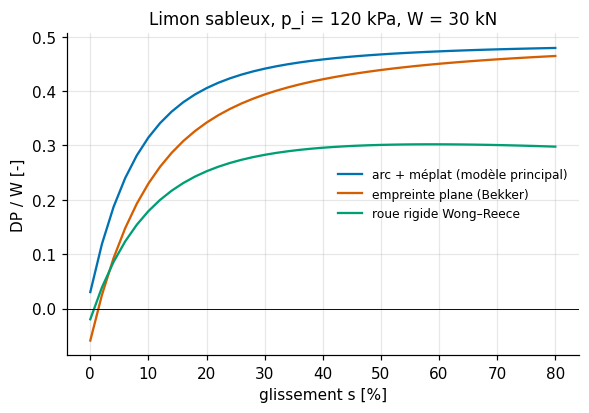

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.8))
soil = SOILS["sandy_loam"]
for mode, lab in (("auto", "arc + méplat (modèle principal)"), ("flat", "empreinte plane (Bekker)"),
                  ("wong_reece", "roue rigide Wong–Reece")):
    df = traction_curve(tire, soil, W, np.linspace(0, 0.8, 41), mode=mode)
    ax.plot(100 * df.slip, df.net_traction_ratio, label=lab)
ax.axhline(0, color="k", lw=0.6)
ax.set(xlabel="glissement s [%]", ylabel="DP / W [-]", title="Limon sableux, p_i = 120 kPa, W = 30 kN")
ax.legend(fontsize=8)
plotting.save(fig, "01_comparaison_modeles");

- L'**empreinte plane** ignore l'arc d'entrée : à $s = 0$, $DP = -R_c$ exactement.
- **Wong–Reece** (roue rigide, maximum de contrainte avancé avec le glissement) prédit un
  enfoncement par patinage (*slip-sinkage*) et donc un maximum d'effort au crochet suivi d'une
  décroissance — comportement observé expérimentalement sur sols meubles.
- L'écart entre formulations (≈ 0,1 sur DP/W) est du même ordre que l'incertitude sur les paramètres de
  sol : **le choix du modèle est en soi une source d'incertitude** à afficher.